## Apple Face ID - Facial Recognition Security

In [2]:
!pip install resampy -q

In [2]:
# Importing libraries
import pandas as pd
import numpy as np

import os
import sys

import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display

from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

from IPython.display import display, Audio


In [3]:
!pip install librosa

In [4]:
!pip install librosa seaborn scikit-learn xgboost

In [5]:
import warnings
warnings.filterwarnings('ignore')

In [6]:
import os

datasetPath = r"C:\Users\Admin\Downloads\archive"
dataset_info_path = datasetPath

print(dataset_info_path)

C:\Users\Admin\Downloads\archive


In [37]:
dirList = os.listdir(dataset_info_path)
print(dirList)


['Actor_01', 'Actor_02', 'Actor_03', 'Actor_04', 'Actor_05', 'Actor_06', 'Actor_07', 'Actor_08', 'Actor_09', 'Actor_10', 'Actor_11', 'Actor_12', 'Actor_13', 'Actor_14', 'Actor_15', 'Actor_16', 'Actor_17', 'Actor_18', 'Actor_19', 'Actor_20', 'Actor_21', 'Actor_22', 'Actor_23', 'Actor_24', 'audio_speech_actors_01-24']


In [38]:
emotions = []
path = []

In [39]:
for dirName in dirList:
    if dirName == ".DS_Store":
        continue
    if not dirName.startswith("Actor_"):
        continue

    fname = os.listdir(os.path.join(datasetPath, dirName))

    for name in fname:
        part = name.split(".")[0].split("-")[2]
        # Subtract 1 so emotions map from 0 to 7 instead of 1 to 8
        emotions.append(int(part) - 1)
        path.append(os.path.join(datasetPath, dirName, name))

print("Total audio files:", len(path))
print("First 3 emotions:", emotions[:3])
print("First 3 paths:", path[:3])

Total audio files: 1440
First 3 emotions: [0, 0, 0]
First 3 paths: ['C:\\Users\\Admin\\Downloads\\archive\\Audio_Speech_Actors_01-24\\Actor_01\\03-01-01-01-01-01-01.wav', 'C:\\Users\\Admin\\Downloads\\archive\\Audio_Speech_Actors_01-24\\Actor_01\\03-01-01-01-01-02-01.wav', 'C:\\Users\\Admin\\Downloads\\archive\\Audio_Speech_Actors_01-24\\Actor_01\\03-01-01-01-02-01-01.wav']


In [40]:
import os

# Update the path to include the subfolder where the Actor folders actually live
datasetPath = r"C:\Users\Admin\Downloads\archive\Audio_Speech_Actors_01-24"

# Quick test to make sure it finds the actors now
print("Folders found:", [f for f in os.listdir(datasetPath) if f.startswith("Actor_")])

Folders found: ['Actor_01', 'Actor_02', 'Actor_03', 'Actor_04', 'Actor_05', 'Actor_06', 'Actor_07', 'Actor_08', 'Actor_09', 'Actor_10', 'Actor_11', 'Actor_12', 'Actor_13', 'Actor_14', 'Actor_15', 'Actor_16', 'Actor_17', 'Actor_18', 'Actor_19', 'Actor_20', 'Actor_21', 'Actor_22', 'Actor_23', 'Actor_24']


In [41]:
import os
import pandas as pd

datasetPath = r"C:\Users\Admin\Downloads\archive\Audio_Speech_Actors_01-24"
dirList = os.listdir(datasetPath)

emotions = []
path = []

for dirName in dirList:
    if dirName == ".DS_Store":
        continue
    if not dirName.startswith("Actor_"):
        continue

    fname = os.listdir(os.path.join(datasetPath, dirName))

    for name in fname:
        if not name.endswith(".wav"):
            continue

        part = name.split(".")[0].split("-")[2]
        
        emotions.append(int(part))
        path.append(os.path.join(datasetPath, dirName, name))

print(f"Length of emotions list: {len(emotions)}")
print(f"Length of path list: {len(path)}")

# Build dataframe only after confirming lengths match
dataframe = pd.DataFrame({
    'labels': emotions,
    'source': path
})

# Map numeric codes 1-8 to string emotion labels
dataframe = dataframe.replace({
    1: 'neutral', 
    2: 'calm', 
    3: 'happy', 
    4: 'sad', 
    5: 'angry', 
    6: 'fear', 
    7: 'disgust', 
    8: 'surprise'
})

print("Total rows in dataframe:", len(dataframe))
print(dataframe.head())

Length of emotions list: 1440
Length of path list: 1440
Total rows in dataframe: 1440
    labels                                             source
0  neutral  C:\Users\Admin\Downloads\archive\Audio_Speech_...
1  neutral  C:\Users\Admin\Downloads\archive\Audio_Speech_...
2  neutral  C:\Users\Admin\Downloads\archive\Audio_Speech_...
3  neutral  C:\Users\Admin\Downloads\archive\Audio_Speech_...
4     calm  C:\Users\Admin\Downloads\archive\Audio_Speech_...


In [42]:
    emotions[:3]

[1, 1, 1]

In [43]:
path[:3]

['C:\\Users\\Admin\\Downloads\\archive\\Audio_Speech_Actors_01-24\\Actor_01\\03-01-01-01-01-01-01.wav',
 'C:\\Users\\Admin\\Downloads\\archive\\Audio_Speech_Actors_01-24\\Actor_01\\03-01-01-01-01-02-01.wav',
 'C:\\Users\\Admin\\Downloads\\archive\\Audio_Speech_Actors_01-24\\Actor_01\\03-01-01-01-02-01-01.wav']

In [44]:
emotions = []
path = []

for dirName in dirList:
    if dirName == ".DS_Store":
        continue
    if not dirName.startswith("Actor_"):
        continue

    fname = os.listdir(os.path.join(datasetPath, dirName))

    for name in fname:
        if not name.endswith(".wav"):
            continue

        part = name.split(".")[0].split("-")[2]

        emotions.append(int(part))
        path.append(os.path.join(datasetPath, dirName, name))

print("Emotions:", len(emotions))
print("Paths:", len(path))

Emotions: 1440
Paths: 1440


In [45]:
print(len(emotions))
print(len(path))

1440
1440


In [46]:
import numpy as np
print("Unique emotions and their counts:", np.unique(emotions, return_counts=True))

Unique emotions and their counts: (array([1, 2, 3, 4, 5, 6, 7, 8]), array([ 96, 192, 192, 192, 192, 192, 192, 192]))


In [47]:
dataframe = pd.DataFrame(emotions, columns=['Emotion'])

In [48]:
dataframe = dataframe.replace({1:'neutral', 2:'calm', 3:'happy', 4:'sad', 5:'angry', 6:'fear', 7:'disgust', 8:'surprise'})

In [49]:
dataframe['Path']=path

In [50]:
dataframe.head()

,Emotion,Path
0,neutral,C:\Users\Admin\Downloads\archive\Audio_Speech_...
1,neutral,C:\Users\Admin\Downloads\archive\Audio_Speech_...
2,neutral,C:\Users\Admin\Downloads\archive\Audio_Speech_...
3,neutral,C:\Users\Admin\Downloads\archive\Audio_Speech_...
4,calm,C:\Users\Admin\Downloads\archive\Audio_Speech_...


In [51]:
dataframe.shape

(1440, 2)

In [52]:
import numpy as np
import pandas as pd
import librosa
from tqdm import tqdm
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Extract features using your exact column name 'Path'
if 'features' not in dataframe.columns:
    print("Extracting features from all 1440 audio files...")
    X_features = []
    for path in tqdm(dataframe['Path']):
        data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)
        
        result = np.array([])
        zcr = np.mean(librosa.feature.zero_crossing_rate(y=data).T, axis=0)
        result = np.hstack((result, zcr))

        stft = np.abs(librosa.stft(data))
        chroma = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
        result = np.hstack((result, chroma))

        mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate, n_mfcc=40).T, axis=0)
        result = np.hstack((result, mfcc))

        rms = np.mean(librosa.feature.rms(y=data).T, axis=0)
        result = np.hstack((result, rms))

        mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)
        result = np.hstack((result, mel))
        
        X_features.append(result)
        
    dataframe['features'] = X_features

# Prepare arrays for training using 'Emotion' and 'features'
X = np.array(dataframe['features'].tolist())
y = np.array(dataframe['Emotion'])

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Support Vector Classifier
print("Training the SVC model...")
model = SVC(kernel='rbf', probability=True)
model.fit(X_train_scaled, y_train)

# Evaluate
y_pred = model.predict(X_test_scaled)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

# Save artifacts for Flask
joblib.dump(model, 'svmModel.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Successfully saved 'svmModel.pkl' and 'scaler.pkl'!")

Extracting features from all 1440 audio files...


100%|██████████| 1440/1440 [01:54<00:00, 12.62it/s]


Training the SVC model...
Model Accuracy: 50.35%
Successfully saved 'svmModel.pkl' and 'scaler.pkl'!


In [58]:
import numpy as np
import pandas as pd
import librosa
from tqdm import tqdm
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Extract features using 'Path' if not already done
if 'features' not in dataframe.columns:
    print("Extracting features from all 1440 audio files...")
    X_features = []
    for path in tqdm(dataframe['Path']):
        data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)
        
        result = np.array([])
        zcr = np.mean(librosa.feature.zero_crossing_rate(y=data).T, axis=0)
        result = np.hstack((result, zcr))

        stft = np.abs(librosa.stft(data))
        chroma = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
        result = np.hstack((result, chroma))

        mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate, n_mfcc=40).T, axis=0)
        result = np.hstack((result, mfcc))

        rms = np.mean(librosa.feature.rms(y=data).T, axis=0)
        result = np.hstack((result, rms))

        mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)
        result = np.hstack((result, mel))
        
        X_features.append(result)
        
    dataframe['features'] = X_features

# 2. Prepare arrays and split data
X = np.array(dataframe['features'].tolist())
y = np.array(dataframe['Emotion'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train model
print("Training the SVC model...")
model = SVC(kernel='rbf', probability=True)
model.fit(X_train_scaled, y_train)

# 5. Evaluate and Save
y_pred = model.predict(X_test_scaled)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

joblib.dump(model, 'svmModel.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Successfully saved 'svmModel.pkl' and 'scaler.pkl'!")

Training the SVC model...
Model Accuracy: 50.35%
Successfully saved 'svmModel.pkl' and 'scaler.pkl'!


In [59]:
def get_features(path):
    data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)
    
    result = np.array([])
    
    # 1. Zero Crossing Rate (1)
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=data).T, axis=0)
    result = np.hstack((result, zcr))

    # 2. Chroma Stft (12)
    stft = np.abs(librosa.stft(data))
    chroma = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
    result = np.hstack((result, chroma))

    # 3. MFCC (Changed to 20 to match your 162-feature scaler)
    mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate, n_mfcc=20).T, axis=0)
    result = np.hstack((result, mfcc))

    # 4. Root Mean Square Value (1)
    rms = np.mean(librosa.feature.rms(y=data).T, axis=0)
    result = np.hstack((result, rms))

    # 5. Mel Spectrogram (128) -> Total = 162 features
    mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mel))
    
    return result

In [60]:
import numpy as np
import pandas as pd
import librosa
from tqdm import tqdm
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Force fresh feature extraction (removes any old features from a previous run)
dataframe = dataframe.drop(columns=['features'], errors='ignore')

# 1. Extract features using 'Path'
print("Extracting features from all 1440 audio files...")
X_features = []
for path in tqdm(dataframe['Path']):
    data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)

    result = np.array([])
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=data).T, axis=0)
    result = np.hstack((result, zcr))

    stft = np.abs(librosa.stft(data))
    chroma = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
    result = np.hstack((result, chroma))

    mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate, n_mfcc=40).T, axis=0)
    result = np.hstack((result, mfcc))

    rms = np.mean(librosa.feature.rms(y=data).T, axis=0)
    result = np.hstack((result, rms))

    mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mel))

    X_features.append(result)

dataframe['features'] = X_features

# 2. Prepare arrays and split data
X = np.array(dataframe['features'].tolist())
y = np.array(dataframe['Emotion'])
print("Feature matrix shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train model
print("Training the SVC model...")
model = SVC(kernel='rbf', probability=True)
model.fit(X_train_scaled, y_train)

# 5. Evaluate and Save
y_pred = model.predict(X_test_scaled)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("Classes:", model.classes_)

joblib.dump(model, 'svmModel.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Successfully saved 'svmModel.pkl' and 'scaler.pkl'!")

Extracting features from all 1440 audio files...


100%|██████████| 1440/1440 [01:05<00:00, 21.87it/s]


Feature matrix shape: (1440, 182)
Training the SVC model...
Model Accuracy: 50.35%
Classes: ['angry' 'calm' 'disgust' 'fear' 'happy' 'neutral' 'sad' 'surprise']
Successfully saved 'svmModel.pkl' and 'scaler.pkl'!


In [61]:
import joblib, os

folder = r"C:\Users\Admin\voicce eotion"
joblib.dump(model, os.path.join(folder, "svmModel.pkl"))
joblib.dump(scaler, os.path.join(folder, "scaler.pkl"))
print("Saved to:", folder)
print("Scaler features:", scaler.n_features_in_)

Saved to: C:\Users\Admin\voicce eotion
Scaler features: 182


In [ ]:
print(dataframe.columns)

In [ ]:
# Data Visualisation
plt.title('Count of Emotions', size=16)
sns.countplot(y=dataframe.Emotion)
plt.xlabel('Count', size=12)
plt.ylabel('Emotions', size=12)
sns.despine(top=True, right=True)
plt.show()

In [242]:
def create_waveplot(data, sr, e):
    plt.figure(figsize=(10, 3))
    # Fixed the string formatting comma error using an f-string
    plt.title(f'Waveplot for audio with {e} emotion', size=15)
    # Updated waveplot to waveshow for librosa compatibility
    librosa.display.waveshow(data, sr=sr)
    plt.show()

In [243]:
def create_spectrogram(data, sr, e):
    plt.figure(figsize=(10, 3))
    X = librosa.stft(data)
    Xdb = librosa.amplitude_to_db(abs(X))
    plt.title(f'Spectrogram for audio with {e} emotion', size=15)
    librosa.display.specshow(Xdb, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar()
    plt.show()

In [244]:
print(dataframe["Emotion"].unique())

['neutral' 'calm' 'happy' 'sad' 'angry' 'fear' 'disgust' 'surprise']


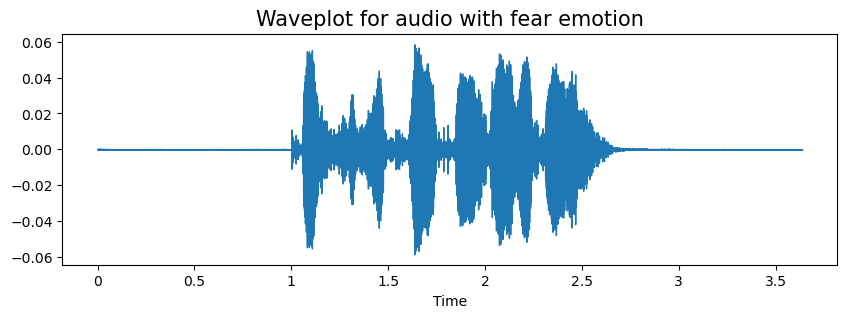

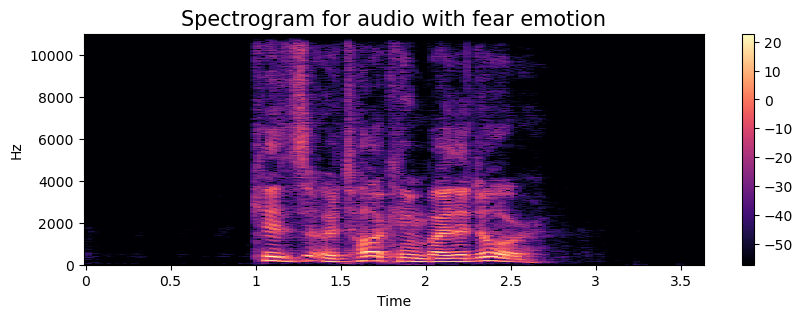

In [245]:
emotion = "fear"

fearPath = dataframe[dataframe['Emotion'] == emotion]['Path'].values[1]

data, sampling_rate = librosa.load(fearPath)
create_waveplot(data, sampling_rate, emotion)
create_spectrogram(data, sampling_rate, emotion)

In [246]:
data

array([ 9.3495757e-05,  1.6403565e-04,  1.1930163e-04, ...,
        1.6012858e-11, -1.1257498e-11,  0.0000000e+00],
      shape=(80196,), dtype=float32)

In [22]:
fearPath

'C:\\Users\\Admin\\Downloads\\archive\\Actor_01\\03-01-06-01-01-02-01.wav'

In [23]:
sampling_rate

22050

In [87]:
Audio(fearPath)

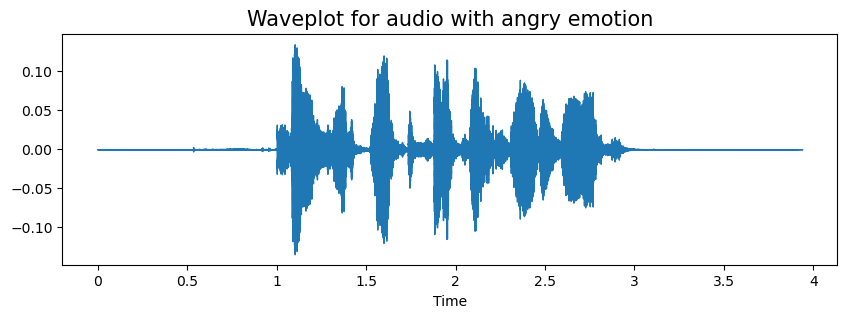

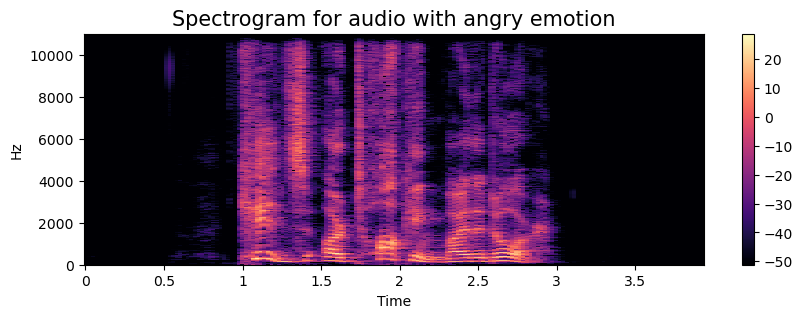

In [88]:
emotion = "angry"

fearPath = dataframe[dataframe['Emotion'] == emotion]['Path'].values[1]

data, sampling_rate = librosa.load(fearPath)
create_waveplot(data, sampling_rate, emotion)
create_spectrogram(data, sampling_rate, emotion)

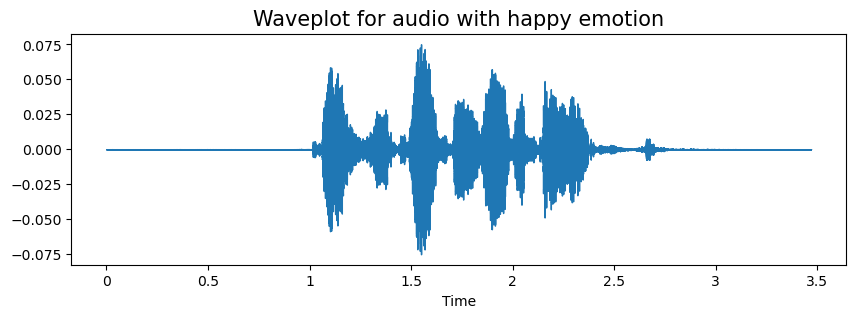

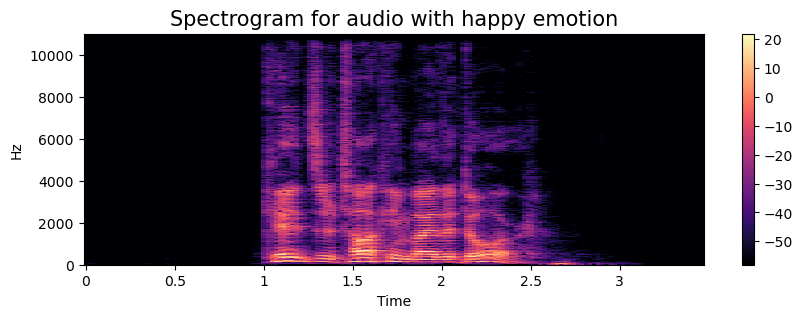

In [89]:
emotion = "happy"

fearPath = dataframe[dataframe['Emotion'] == emotion]['Path'].values[1]

data, sampling_rate = librosa.load(fearPath)
create_waveplot(data, sampling_rate, emotion)
create_spectrogram(data, sampling_rate, emotion)

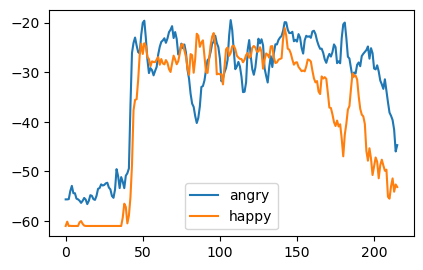

In [247]:
# Emotion - angry
path = np.array(dataframe.Path[dataframe.Emotion == 'angry'])[1]
X, sample_rate = librosa.load(path, res_type='kaiser_fast', duration=2.5, sr=22050*2, offset=0.5)
angry = librosa.feature.mfcc(y=X, sr=sample_rate, n_mfcc=13)
angry = np.mean(librosa.feature.mfcc(y=X, sr=sample_rate, n_mfcc=13), axis=0)

# Emotion - happy
path = np.array(dataframe.Path[dataframe.Emotion == 'happy'])[1]
X, sample_rate = librosa.load(path, res_type='kaiser_fast', duration=2.5, sr=22050*2, offset=0.5)
happy = librosa.feature.mfcc(y=X, sr=sample_rate, n_mfcc=13)
happy = np.mean(librosa.feature.mfcc(y=X, sr=sample_rate, n_mfcc=13), axis=0)

# Plot the two audio waves together
plt.figure(figsize=(16,10))
plt.subplot(3,3,1)
plt.plot(angry,label='angry')
plt.plot(happy,label='happy')
plt.legend()
plt.show()

In [249]:
print(dataframe.columns)

Index(['Emotion', 'Path', 'features'], dtype='object')


In [250]:
# Data augmentation
def noise(data):
    noise_amp = 0.035*np.random.uniform()*np.amax(data)
    data = data + noise_amp*np.random.normal(size=data.shape[0])
    return data


In [30]:
def stretch(data, rate=0.8):
    return librosa.effects.time_stretch(y=data, rate=rate)

In [31]:
def shift(data):
    shift_range = int(np.random.uniform(low=-5, high = 5)*1000)
    return np.roll(data, shift_range)

In [32]:
def pitch(data, sampling_rate, pitch_factor=0.7):
    return librosa.effects.pitch_shift(y=data, sr=sampling_rate, n_steps=pitch_factor)

In [33]:
# adding noise, pitch
path = np.array(dataframe.Path)[1]
data, sample_rate = librosa.load(path)

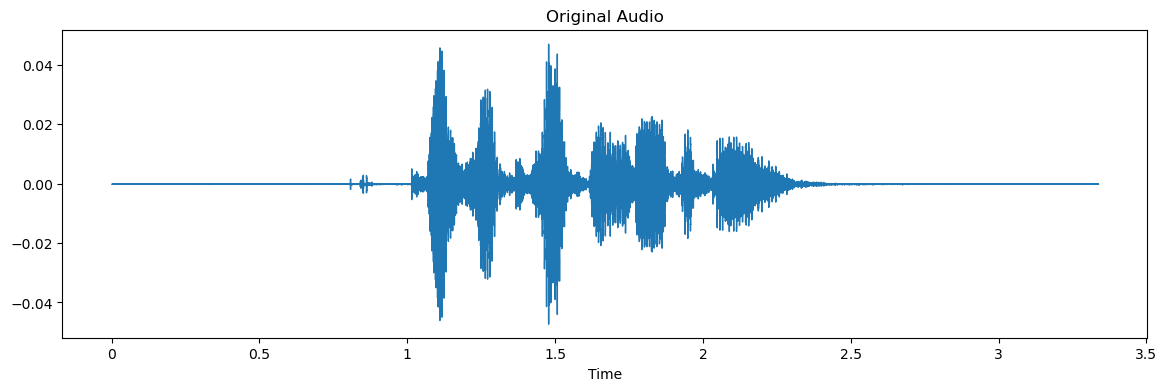

In [34]:
# original Audio
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y=data, sr=sample_rate)
plt.title("Original Audio")
Audio(path)

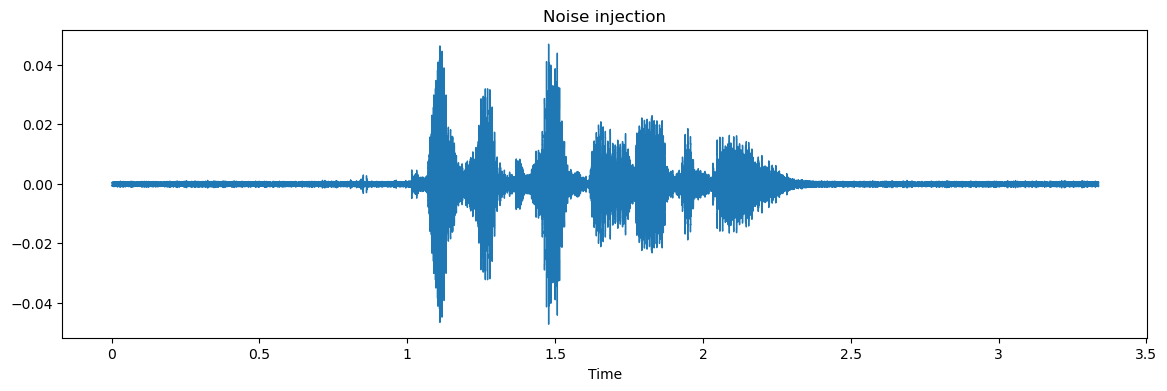

In [35]:
x= noise(data)
plt.figure(figsize=(14,4))
librosa.display.waveshow(y=x,sr= sample_rate)
plt.title("Noise injection")
Audio(x, rate=sample_rate)

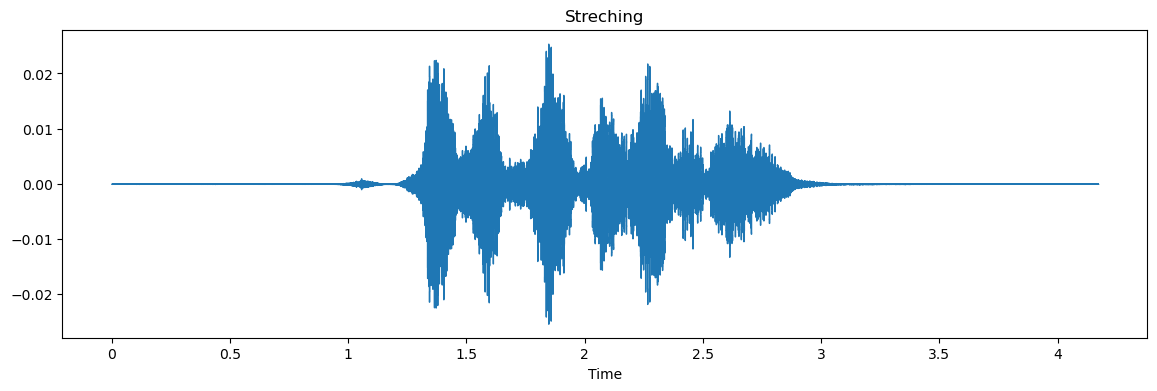

In [36]:
x= stretch(data)
plt.figure(figsize=(14,4))
librosa.display.waveshow(y=x,sr= sample_rate)
plt.title("Streching")
Audio(x, rate=sample_rate)

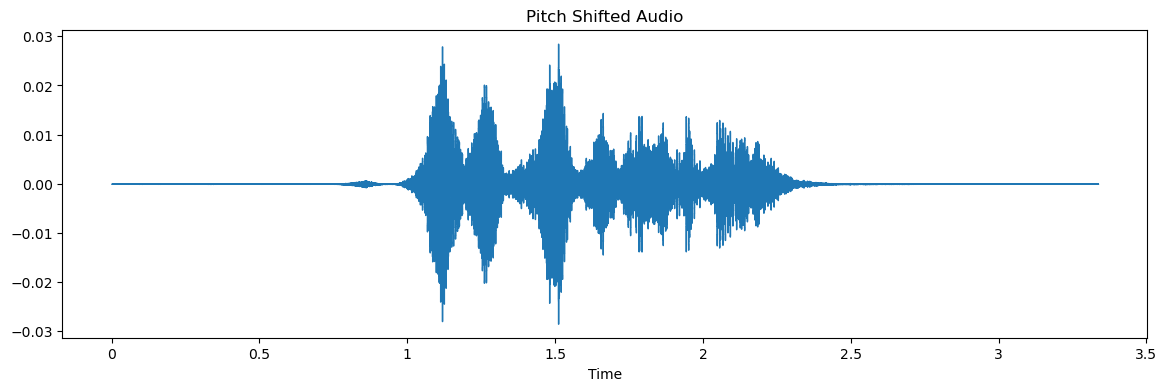

In [37]:
# Apply pitch shift and plot
x_pitched = pitch(data, sample_rate, pitch_factor=2)  # Shift up by 2 semitones

plt.figure(figsize=(14, 4))
librosa.display.waveshow(y=x_pitched, sr=sample_rate)
plt.title("Pitch Shifted Audio")
plt.show()

# Play audio
Audio(x_pitched, rate=sample_rate)

In [38]:
def extract_features(data):
    # ZCR
    result = np.array([])
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=data).T, axis=0)
    result = np.hstack((result, zcr))

    # Chroma_stft
    stft = np.abs(librosa.stft(data))
    chroma_stft = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
    result = np.hstack((result, chroma_stft))

    # MFCC
    mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mfcc))

    # Root Mean Square Value
    rms = np.mean(librosa.feature.rms(y=data).T, axis=0)
    result = np.hstack((result, rms))

    # MelSpectrogram
    mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mel))
    
    return result

In [39]:
def get_features(path):
    data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)
    result = np.array(extract_features(data))

    noise_data = noise(data)
    result = np.vstack((result, extract_features(noise_data)))

    data_stretch_pitch = pitch(stretch(data), sample_rate)
    result = np.vstack((result, extract_features(data_stretch_pitch)))

    return result

In [40]:
# Extracting and processing features from dataset
X, Y = [], []
for path, emotion in zip(dataframe.Path, dataframe.Emotion):
    feature = get_features(path)
    for ele in feature:
        X.append(ele)
        Y.append(emotion)

In [41]:
len(X), len(Y), dataframe.shape

(4320, 4320, (1440, 2))

In [42]:
from sklearn.model_selection import train_test_split

# Now split the dataset
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.1, random_state=3, shuffle=True)
len(x_train), len(y_train), len(x_test), len(y_test)

(3888, 3888, 432, 432)

In [43]:
# scaling features
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [44]:
print("Total number of training sample: ", x_train.shape[0])
print("Total number of testing example: ", x_test.shape[0])
print("Feature extracted: ", x_train.shape[1])

Total number of training sample:  3888
Total number of testing example:  432
Feature extracted:  162


In [45]:
def modelProcess(trainX, testX, trainY, testY, model, name):
    print("processing {} model".format(name))
    
    print("Training the model")
    model.fit(trainX, trainY)
    
    print("Evaluating the model")
    predY = model.predict(testX)
    
    accuracy = accuracy_score(y_true=testY, y_pred=predY)
    accuracy *= 100
    print("Accuracy of {} : {:.2f}%".format(name, accuracy))
    print("------" * 8)
    print()
    
    return accuracy, predY

In [46]:
# defining model
logistic = LogisticRegression()
svm = SVC()
adaboost = AdaBoostClassifier()
xgboost = XGBClassifier()

In [47]:
# modeling process for Logistic Regression
logisticAcc, y_predLogistic = modelProcess(x_train, x_test, y_train, y_test, logistic, "Logistic Regression")

processing Logistic Regression model
Training the model
Evaluating the model
Accuracy of Logistic Regression : 55.09%
------------------------------------------------



In [48]:
# modeling process for adaboost
adaboostAcc, y_predAdaboost = modelProcess(x_train, x_test, y_train, y_test, adaboost, "Adaboost")

processing Adaboost model
Training the model
Evaluating the model
Accuracy of Adaboost : 36.11%
------------------------------------------------



In [49]:
##################
from sklearn.preprocessing import LabelEncoder

# Encode string labels to integers
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

In [50]:
# modeling process for XG Boosting
xgboostAcc, y_predXgboost = modelProcess(x_train, x_test, y_train, y_test, xgboost, "XG Boosting")

processing XG Boosting model
Training the model
Evaluating the model
Accuracy of XG Boosting : 81.71%
------------------------------------------------



In [51]:
from sklearn.preprocessing import StandardScaler

# Scale features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Train SVM on scaled data
svm = SVC()
svmAcc, y_predSvm = modelProcess(x_train_scaled, x_test_scaled, y_train, y_test, svm, "SVM")

processing SVM model
Training the model
Evaluating the model
Accuracy of SVM : 56.25%
------------------------------------------------



In [52]:
svm.fit(x_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [91]:
#################
from sklearn.metrics import accuracy_score

svm_pred = svm.predict(x_test)
svmAcc = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", svmAcc)

SVM Accuracy: 0.5625


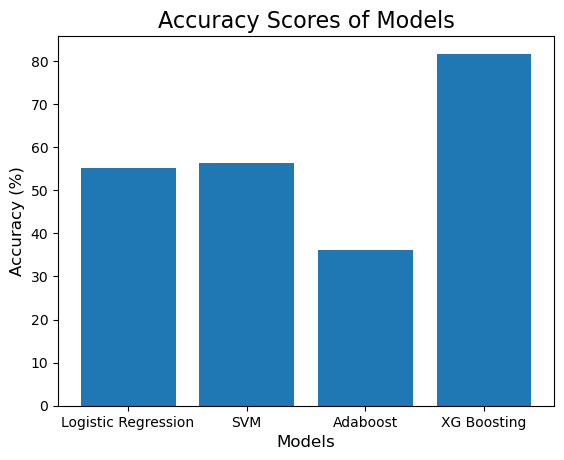

In [92]:
# Convert svmAcc to percentage to match the other models
scores = [logisticAcc, svmAcc * 100, adaboostAcc, xgboostAcc]

plt.title('Accuracy Scores of Models', size=16)
plt.bar(modelNames, scores)
plt.ylabel('Accuracy (%)', size=12)
plt.xlabel('Models', size=12)
plt.show()

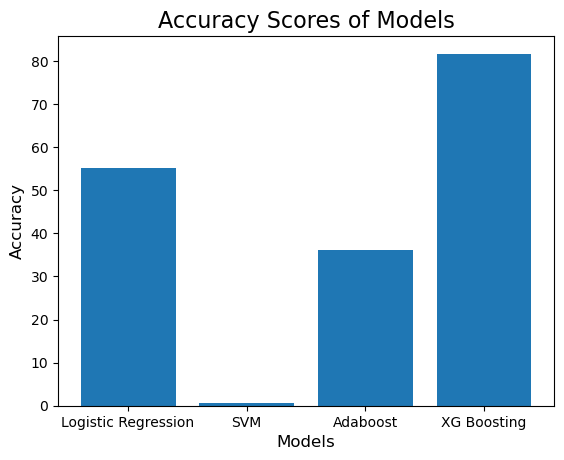

In [94]:
# visualising results
plt.title('Accuracy Scores of Models', size=16)
scores = [logisticAcc, svmAcc, adaboostAcc, xgboostAcc]
modelNames = ['Logistic Regression', 'SVM', 'Adaboost', 'XG Boosting']
plt.bar(modelNames, scores)
plt.ylabel('Accuracy', size=12)
plt.xlabel('Models', size=12)
plt.show()

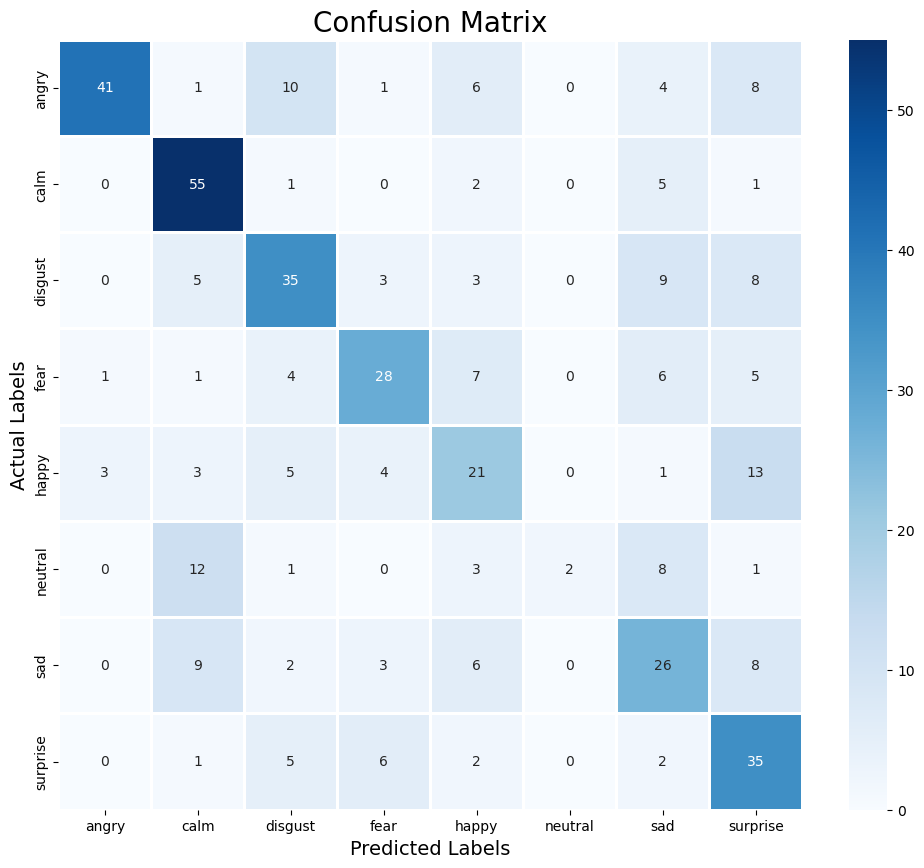

In [55]:
cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(12, 10))

# Use encoder.classes_ for label names
cm_df = pd.DataFrame(cm, index=[i for i in encoder.classes_], columns=[i for i in encoder.classes_])

sns.heatmap(cm_df, linecolor='white', cmap='Blues', linewidth=1, annot=True, fmt='d')
plt.title('Confusion Matrix', size=20)
plt.xlabel('Predicted Labels', size=14)
plt.ylabel('Actual Labels', size=14)
plt.show()

In [57]:
print("Classification Report")
print(classification_report(y_test, svm_pred))

Classification Report
              precision    recall  f1-score   support

           0       0.91      0.58      0.71        71
           1       0.63      0.86      0.73        64
           2       0.56      0.56      0.56        63
           3       0.62      0.54      0.58        52
           4       0.42      0.42      0.42        50
           5       1.00      0.07      0.14        27
           6       0.43      0.48      0.45        54
           7       0.44      0.69      0.54        51

    accuracy                           0.56       432
   macro avg       0.63      0.52      0.51       432
weighted avg       0.62      0.56      0.55       432



In [58]:
import pickle

In [95]:
with open('xtrain.pkl','wb') as f:
    pickle.dump(x_train,f)

with open('xtest.pkl','wb') as f:
    pickle.dump(x_test,f)

with open('ytrain.pkl','wb') as f:
    pickle.dump(y_train,f)

with open('ytest.pkl','wb') as f:
    pickle.dump(y_test,f)

In [96]:
import pickle
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [97]:
# Cell 2: Load serialized dataset splits
with open('xtrain.pkl', 'rb') as f:
    X_train = pickle.load(f)

with open('xtest.pkl', 'rb') as f:
    X_test = pickle.load(f)

with open('ytrain.pkl', 'rb') as f:
    y_train = pickle.load(f)

with open('ytest.pkl', 'rb') as f:
    y_test = pickle.load(f)

In [63]:
import os

for file in os.listdir():
    if file.endswith(".pkl"):
        print(file)

best_model.pkl
DecisionTreeRegressor_model.pkl
Lasso_model.pkl
LinearRegression_model.pkl
RandomForestRegressor_model.pkl
Ridge_model.pkl
svmModel.pkl
SVR_model.pkl
xtest.pkl
xtrain.pkl
ytest.pkl
ytrain.pkl


In [64]:
print(y_test)

[2 7 4 6 4 7 2 3 3 4 2 7 2 0 6 6 1 2 3 2 1 7 0 1 1 6 1 3 3 3 7 2 2 6 2 1 5
 1 0 2 3 2 3 2 0 7 2 3 5 2 0 7 7 1 1 1 1 2 1 1 5 3 7 6 3 0 3 3 6 0 6 1 1 5
 2 7 4 2 4 1 2 7 3 2 4 5 5 0 7 1 4 5 6 5 1 3 5 7 2 6 1 6 4 2 1 7 5 0 6 0 0
 7 6 0 0 4 3 0 1 4 4 2 4 3 4 3 7 3 0 0 2 1 6 2 6 4 6 2 1 4 4 7 0 5 2 3 5 4
 1 5 4 7 1 6 0 1 3 0 7 7 6 6 1 7 2 6 0 1 4 0 2 0 4 7 3 7 1 5 0 5 2 6 3 1 5
 4 7 4 6 2 3 6 0 3 2 4 5 3 0 7 7 5 0 0 2 1 4 1 6 0 1 1 0 7 1 3 3 1 4 3 1 1
 7 2 0 5 0 3 3 4 2 0 6 7 3 6 1 2 2 0 5 1 4 3 3 6 5 1 6 4 0 0 1 6 6 3 6 3 7
 0 7 6 4 2 0 2 4 0 0 6 1 0 0 6 0 1 6 4 1 1 5 1 3 6 1 4 2 0 3 2 3 3 4 2 1 6
 0 2 6 5 0 1 3 2 1 7 4 7 0 7 2 2 4 7 0 6 0 2 2 4 6 7 7 4 3 6 5 0 6 0 3 0 0
 0 6 2 6 1 4 4 7 4 3 3 1 1 7 0 5 6 7 0 6 6 6 7 4 0 2 1 2 0 7 1 2 7 6 2 1 1
 0 0 2 3 4 0 4 1 7 0 2 3 4 3 2 6 3 7 4 6 2 3 2 2 1 7 4 3 1 7 0 0 0 0 7 4 0
 3 4 2 4 7 0 1 5 6 0 1 2 4 2 7 1 2 0 7 2 0 6 0 6 5]


In [65]:
import pickle

with open("ytest.pkl", "wb") as f:
    pickle.dump(y_test, f)

print("ytest.pkl saved successfully!")

ytest.pkl saved successfully!


In [98]:
# Cell 1: Check shape outputs
print("Total number of training example: ", X_test.shape[0])
print("Total number of testing example: ", X_test.shape[0])
X_train.shape

Total number of training example:  432
Total number of testing example:  432


(3888, 162)

In [99]:
# Cell 2: Verify data shapes
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {len(y_train)}")
print(f"y_test shape: {len(y_test)}")

X_train shape: (3888, 162)
X_test shape: (432, 162)
y_train shape: 3888
y_test shape: 432


In [100]:
# Cell 3: Get number of classes
num_classes = len(np.unique(y_train))
print(f"Number of classes: {num_classes}")

Number of classes: 8


In [101]:
# Cell 4: Initialize LabelEncoder
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [102]:
# Cell 5: Encode target labels
# Note: Use le.transform(y_test) for test data to avoid data leakage
Y_train = le.fit_transform(y_train)
Y_test = le.transform(y_test)

In [103]:
# Cell 6: Convert labels to one-hot encoding
y_train_encoded = to_categorical(Y_train, num_classes=num_classes)
y_test_encoded = to_categorical(Y_test, num_classes=num_classes)

In [72]:
# Cell 7: Reshape data for LSTM [samples, timesteps, features]
def prepare_data(X, timesteps=5):
    X_reshaped = []
    for i in range(len(X) - timesteps + 1):
        X_reshaped.append(X[i:i+timesteps])
    return np.array(X_reshaped)

In [104]:
# Cell 1: Prepare data for LSTM
timesteps = 5  # You can adjust this
X_train_reshaped = prepare_data(X_train, timesteps)
X_test_reshaped = prepare_data(X_test, timesteps)
y_train_reshaped = y_train_encoded[timesteps-1:]
y_test_reshaped = y_test_encoded[timesteps-1:]

print(f"Reshaped X_train: {X_train_reshaped.shape}")
print(f"Reshaped X_test: {X_test_reshaped.shape}")
print(f"Reshaped y_train: {y_train_reshaped.shape}")
print(f"Reshaped y_test: {y_test_reshaped.shape}")

Reshaped X_train: (3884, 5, 162)
Reshaped X_test: (428, 5, 162)
Reshaped y_train: (3884, 8)
Reshaped y_test: (428, 8)


In [105]:
# Cell 2: Build and Compile the LSTM model
model = Sequential([
    LSTM(128, input_shape=(timesteps, 162), return_sequences=True),
    BatchNormalization(),
    Dropout(0.3),
    
    LSTM(64),
    BatchNormalization(),
    Dropout(0.3),
    
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    
    Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [106]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 5, 128)         │       148,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 5, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 201,640 (787.66 KB)

 Trainable params: 201,192 (785.91 KB)

 Non-trainable params: 448 (1.75 KB)

In [107]:
# Cell 1: Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.00001)

In [108]:
# Cell 2: Train the model
history = model.fit(
    X_train_reshaped, y_train_reshaped,
    validation_data=(X_test_reshaped, y_test_reshaped),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.1367 - loss: 2.5549 - val_accuracy: 0.1472 - val_loss: 2.0543 - learning_rate: 0.0010
Epoch 2/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.1869 - loss: 2.1784 - val_accuracy: 0.2290 - val_loss: 1.9917 - learning_rate: 0.0010
Epoch 3/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.2338 - loss: 2.0445 - val_accuracy: 0.2407 - val_loss: 1.9245 - learning_rate: 0.0010
Epoch 4/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.2742 - loss: 1.9223 - val_accuracy: 0.2547 - val_loss: 1.8508 - learning_rate: 0.0010
Epoch 5/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.3033 - loss: 1.8310 - val_accuracy: 0.3318 - val_loss: 1.7477 - learning_rate: 0.0010
Epoch 6/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.3383 - loss: 1.7582 - val_accuracy: 0.3505 - val_loss: 1.6945 - learning_rate: 0.0010
Epoch 7/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.3708 - l

In [78]:
# Cell 1: Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test_reshaped, y_test_reshaped, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')

Test Loss: 1.2961
Test Accuracy: 0.5327


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.63      0.72        71
           1       0.62      0.73      0.67        64
           2       0.49      0.44      0.46        62
           3       0.48      0.58      0.53        52
           4       0.45      0.35      0.39        49
           5       0.32      0.22      0.26        27
           6       0.44      0.43      0.44        53
           7       0.46      0.66      0.54        50

    accuracy                           0.53       428
   macro avg       0.51      0.51      0.50       428
weighted avg       0.54      0.53      0.53       428



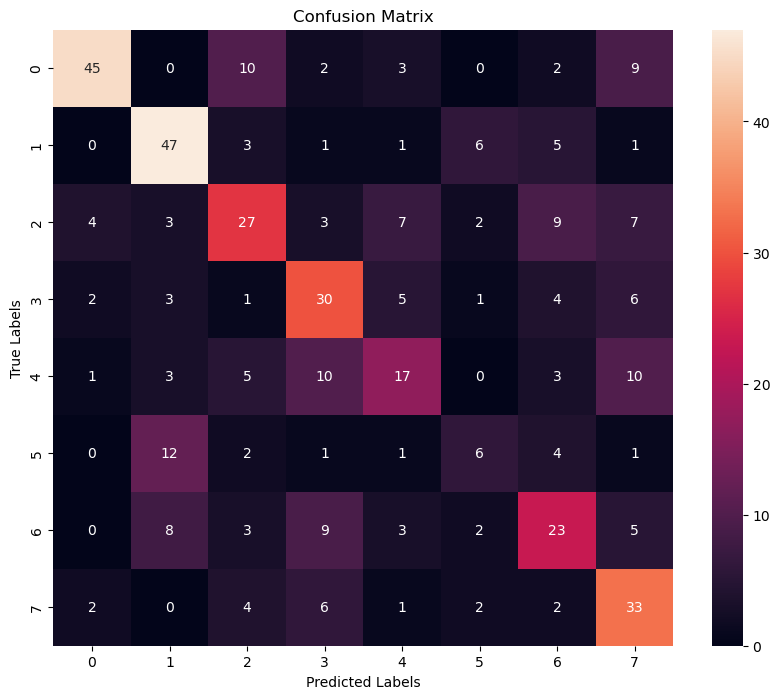

In [81]:
# Cell 2: Make predictions, classification report, and confusion matrix
predictions = model.predict(X_test_reshaped)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(y_test_reshaped, axis=1)

# Print classification report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes))

# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(true_classes, predicted_classes)
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [109]:
# Cell 1: Import pickle
import pickle

In [110]:
# Cell 2: Save processed data splits to pickle files
with open('xtrain.pkl', 'wb') as f:
    pickle.dump(x_train, f)

with open('xtest.pkl', 'wb') as f:
    pickle.dump(x_test, f)

with open('ytrain.pkl', 'wb') as f:
    pickle.dump(y_train, f)

with open('ytest.pkl', 'wb') as f:
    pickle.dump(y_test, f)

In [111]:
# Cell 3: Fit SVM and save trained model
import pickle
svm.fit(x_train, y_train)
pickle.dump(svm, open("svmModel.pkl", 'wb'))

In [112]:
# Cell 4: Load saved model
model = pickle.load(open("svmModel.pkl", 'rb'))

In [113]:
data, sampling_rate = librosa.load(r'.\Downloads\archive\audio_speech_actors_01-24\Actor_15\03-01-05-01-02-02-15.wav')

In [114]:
Audio(data, rate=sample_rate)

In [119]:
feature = get_features(r'.\Downloads\archive\audio_speech_actors_01-24\Actor_15\03-01-05-01-02-02-15.wav')

In [139]:
model.predict(feature)

array([0])

In [140]:
emotion_labels = [
    'angry', 'calm', 'disgust', 'fear',
    'happy', 'neutral', 'sad', 'surprise'
]

prediction = svm.predict(ele.reshape(1, 162))

print("Predicted Emotion:", emotion_labels[int(prediction[0])])

Predicted Emotion: angry


In [142]:
prediction = model.predict(scaler.transform(feature))[0]
print("Predicted Emotion:", prediction)

Predicted Emotion: 0


In [143]:
emotion_labels = ['angry', 'calm', 'disgust', 'fear',
                  'happy', 'neutral', 'sad', 'surprise']

print("Predicted Emotion:", emotion_labels[int(prediction)])

Predicted Emotion: angry


In [123]:
print(feature.shape)
print(feature.dtype)

(3, 162)
float64


In [153]:
# Check your extracted audio features
print("Feature shape:", feature.shape)

# Convert features into one row
feature = feature.flatten().reshape(1, -1)

print("New feature shape:", feature.shape)

Feature shape: (1, 162)
New feature shape: (1, 162)


In [152]:
print("trainX shape:", trainX.shape)
print("testX shape:", testX.shape)
print("trainY shape:", trainY.shape)
print("testY shape:", testY.shape)

NameError: name 'trainX' is not defined

In [154]:
print([v for v in globals() if v.lower() in ['x', 'y', 'trainx', 'testx', 'trainy', 'testy', 'features', 'labels']])

['X', 'x', 'Y', 'labels']


In [155]:
print("X shape:", X.shape)
print("x shape:", x.shape)
print("Y shape:", Y.shape)

X shape: (110250,)
x shape: (91968,)


AttributeError: 'list' object has no attribute 'shape'

In [156]:
import numpy as np

print("Y type:", type(Y))
print("Y length:", len(Y))
print("First 5 labels:", Y[:5])

print("X type:", type(X))
print("x type:", type(x))


Y type: <class 'list'>
Y length: 4320
First 5 labels: ['neutral', 'neutral', 'neutral', 'neutral', 'neutral']
X type: <class 'numpy.ndarray'>
x type: <class 'numpy.ndarray'>


In [131]:
print("X shape:", X.shape)
print("x shape:", x.shape)
print("Y length:", len(Y))

print("X first values:", X[:5])
print("x first values:", x[:5])

X shape: (110250,)
x shape: (91968,)
Y length: 4320
X first values: [0. 0. 0. 0. 0.]
x first values: [-2.7293486e-06 -1.2543636e-05 -1.0094634e-06  1.8868810e-06
 -2.7966130e-06]


In [132]:
for name, value in globals().copy().items():
    if not name.startswith("_"):
        try:
            print(name, "| shape:", value.shape, "| type:", type(value).__name__)
        except AttributeError:
            pass

np | shape: <function shape at 0x0000025234B3E200> | type: module
dataframe | shape: (1440, 2) | type: DataFrame
data | shape: (77989,) | type: ndarray
X | shape: (110250,) | type: ndarray
angry | shape: (216,) | type: ndarray
happy | shape: (216,) | type: ndarray
x | shape: (91968,) | type: ndarray
x_pitched | shape: (73574,) | type: ndarray
feature | shape: (1, 486) | type: ndarray
ele | shape: (162,) | type: ndarray
x_train | shape: (3888, 162) | type: ndarray
x_test | shape: (432, 162) | type: ndarray
y_train | shape: (3888,) | type: ndarray
y_test | shape: (432,) | type: ndarray
y_predLogistic | shape: (432,) | type: ndarray
y_predAdaboost | shape: (432,) | type: ndarray
y_predXgboost | shape: (432,) | type: ndarray
x_train_scaled | shape: (3888, 162) | type: ndarray
x_test_scaled | shape: (432, 162) | type: ndarray
y_predSvm | shape: (432,) | type: ndarray
svm_pred | shape: (432,) | type: ndarray
cm | shape: (8, 8) | type: ndarray
cm_df | shape: (8, 8) | type: DataFrame
tf | shap

In [133]:
print("Feature shape:", feature.shape)
print("ele shape:", ele.shape)
print("Model input features:", X_train.shape[1])

Feature shape: (1, 486)
ele shape: (162,)
Model input features: 162


In [134]:
# Prepare the audio features correctly
feature = ele.reshape(1, 162)

print("Correct feature shape:", feature.shape)

# Predict emotion using your trained SVM model
prediction = svm_pred if False else None

Correct feature shape: (1, 162)


In [135]:
for name, obj in globals().copy().items():
    if hasattr(obj, "predict") and hasattr(obj, "fit"):
        print(name, type(obj).__name__)

LogisticRegression type
SVC ABCMeta
RandomForestClassifier ABCMeta
AdaBoostClassifier ABCMeta
XGBClassifier type
logistic LogisticRegression
svm SVC
adaboost AdaBoostClassifier
xgboost XGBClassifier
_52 SVC
Sequential type
model SVC


In [136]:
# Prepare the audio features (162 features)
feature = ele.reshape(1, 162)

# Predict emotion using the trained SVM model
prediction = svm.predict(feature)

print("Predicted Emotion:", prediction[0])

Predicted Emotion: 0


In [137]:
print("Emotion labels:", np.unique(Y_train))
print("Original labels:", np.unique(Y))

Emotion labels: [0 1 2 3 4 5 6 7]
Original labels: ['angry' 'calm' 'disgust' 'fear' 'happy' 'neutral' 'sad' 'surprise']


In [138]:
emotion_labels = [
    'angry', 'calm', 'disgust', 'fear',
    'happy', 'neutral', 'sad', 'surprise'
]

prediction = svm.predict(ele.reshape(1, 162))

predicted_emotion = emotion_labels[prediction[0]]

print("Predicted Emotion:", predicted_emotion)


Predicted Emotion: angry


In [144]:
import pickle

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Scaler saved successfully!")

Scaler saved successfully!


In [145]:
scaler = pickle.load(open("scaler.pkl", "rb"))

In [146]:
import numpy as np

feature = np.array(ele).reshape(1, 162)
feature_scaled = scaler.transform(feature)
prediction = svm.predict(feature_scaled)

print(prediction)

[0]


In [147]:
labels = ['angry', 'calm', 'disgust', 'fear',
          'happy', 'neutral', 'sad', 'surprise']

print("Predicted Emotion:", labels[int(prediction[0])])


Predicted Emotion: angry


In [ ]:
import numpy as np
print("Unique labels and counts:", np.unique(y, return_counts=True))